In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Hotel Booking Data Analysis Using Python
**Course:** Data Preparation and Analysis (M.Tech CSE – Artificial Intelligence)  
**Dataset:** Hotel Booking Demand (Kaggle)  
**Objective:** Perform data preparation, analysis, visualization, and feature engineering using NumPy, Pandas, Matplotlib, and Plotly.

> Dataset source: [Kaggle – Hotel Booking Demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)  
> This notebook expects `hotel_bookings.csv` in the same folder as this notebook.

## Step 1 — Dataset Collection
The dataset contains hotel booking records for City Hotels and Resort Hotels. It includes booking status, dates, guest counts, room details, lead time, prices, and booking channels.

**Problem statement:** Understand booking patterns, cancellation behavior, guest and stay characteristics, and price patterns using descriptive analysis and visualizations.

**Objectives**
- Inspect and understand the data structure.
- Clean missing values, duplicates, data types, and outliers.
- Explore numerical and categorical columns.
- Create static and interactive visualizations.
- Engineer useful features and summarize insights.

In [5]:
# Step 1: Import libraries and load the dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import warnings
warnings.filterwarnings("ignore")


df = pd.read_csv("/content/drive/MyDrive/hotel_bookings.csv")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## Step 2 — NumPy Operations
We use NumPy to work with numerical values and calculate basic statistics. `adr` (average daily rate) and `lead_time` are useful numeric variables.

In [6]:
# Convert selected columns into NumPy arrays
adr_array = df["adr"].to_numpy()
lead_array = df["lead_time"].to_numpy()

# Array creation, indexing, slicing, and arithmetic
sample_array = np.array([10, 20, 30, 40, 50])
print("Array:", sample_array)
print("First element:", sample_array[0])
print("Slice (first 3):", sample_array[:3])
print("Add 5:", sample_array + 5)
print("Multiply by 2:", sample_array * 2)

# Statistical calculations (ignore missing values)
print("\\nADR statistics")
print("Mean:", np.nanmean(adr_array))
print("Median:", np.nanmedian(adr_array))
print("Std dev:", np.nanstd(adr_array))
print("Minimum:", np.nanmin(adr_array))
print("Maximum:", np.nanmax(adr_array))
print("25th, 50th, 75th percentiles:", np.nanpercentile(adr_array, [25, 50, 75]))

print("\\nLead-time statistics")
print("Mean:", np.nanmean(lead_array))
print("Median:", np.nanmedian(lead_array))
print("Std dev:", np.nanstd(lead_array))

Array: [10 20 30 40 50]
First element: 10
Slice (first 3): [10 20 30]
Add 5: [15 25 35 45 55]
Multiply by 2: [ 20  40  60  80 100]
\nADR statistics
Mean: 101.83112153446687
Median: 94.575
Std dev: 50.53557864346769
Minimum: -6.38
Maximum: 5400.0
25th, 50th, 75th percentiles: [ 69.29   94.575 126.   ]
\nLead-time statistics
Mean: 104.01141636652986
Median: 69.0
Std dev: 106.86264950916217


## Step 3 — Pandas Operations
Inspect the dataset's size, columns, data types, records, and descriptive statistics.

In [7]:
print("First five rows:")
display(df.head())
print("Last five rows:")
display(df.tail())
print("Rows and columns:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nData types:")
display(df.dtypes)
print("\\nSummary statistics:")
display(df.describe(include="all").T)
print("\\nMissing values per column:")
display(df.isna().sum().sort_values(ascending=False))
print("\\nDuplicate rows:", df.duplicated().sum())

First five rows:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Last five rows:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


Rows and columns: (119390, 32)
\nColumn names:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']
\nData types:


,0
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


\nSummary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


\nMissing values per column:


,0
company,112593
agent,16340
country,488
children,4
arrival_date_month,0
arrival_date_week_number,0
hotel,0
is_canceled,0
stays_in_weekend_nights,0
arrival_date_day_of_month,0


\nDuplicate rows: 31994


## Step 4 — Data Cleaning and Preprocessing
We preserve the original dataset for comparison. Missing `children` values are filled with zero (the column represents a guest count); missing categorical `country` values are labeled `Unknown`. Missing `agent` and `company` values are retained as missing because they can indicate bookings without those identifiers. Duplicate rows are removed. Column names are standardized to lowercase with underscores. Outliers in `adr` are inspected and an analysis copy excludes negative ADR values and caps extreme ADR values at the 99th percentile for plotting/summary robustness (the original values remain in `df_clean`).

In [8]:
# Keep original for before/after comparison
df_original = df.copy()

# Standardize column names
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# Fill missing values thoughtfully
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")

# Remove duplicate records
duplicates_before = df.duplicated().sum()
df_clean = df.drop_duplicates().copy()

# Convert date-related columns to appropriate types
df_clean["arrival_date_year"] = df_clean["arrival_date_year"].astype("Int64")
df_clean["arrival_date_day_of_month"] = df_clean["arrival_date_day_of_month"].astype("Int64")

# Basic validity check: negative ADR is not meaningful as a room price
negative_adr_count = (df_clean["adr"] < 0).sum()
df_clean = df_clean[df_clean["adr"] >= 0].copy()

print("Duplicates found before removal:", duplicates_before)
print("Rows before cleaning:", len(df_original))
print("Rows after duplicate removal and ADR validity check:", len(df_clean))
print("Negative ADR values removed:", negative_adr_count)
print("Remaining missing values (top):")
display(df_clean.isna().sum().sort_values(ascending=False).head(10))

Duplicates found before removal: 31994
Rows before cleaning: 119390
Rows after duplicate removal and ADR validity check: 87395
Negative ADR values removed: 1
Remaining missing values (top):


,0
company,82136
agent,12193
hotel,0
is_canceled,0
arrival_date_month,0
arrival_date_week_number,0
lead_time,0
arrival_date_year,0
stays_in_week_nights,0
adults,0


In [9]:
# Before vs after cleaning comparison
comparison = pd.DataFrame({
    "Metric": ["Rows", "Columns", "Duplicate rows", "Missing values (total)"],
    "Before": [df_original.shape[0], df_original.shape[1], df_original.duplicated().sum(), df_original.isna().sum().sum()],
    "After": [df_clean.shape[0], df_clean.shape[1], df_clean.duplicated().sum(), df_clean.isna().sum().sum()]
})
display(comparison)

,Metric,Before,After
0,Rows,119390,87395
1,Columns,32,32
2,Duplicate rows,31994,0
3,Missing values (total),129425,94329


### Outlier analysis using the IQR method
The IQR method flags values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. We report the count and create a capped ADR variable for visual analysis; this avoids deleting rows solely because they are unusual.

In [10]:
# IQR outlier detection for ADR
q1 = df_clean["adr"].quantile(0.25)
q3 = df_clean["adr"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
adr_outliers = df_clean[(df_clean["adr"] < lower_bound) | (df_clean["adr"] > upper_bound)]
print(f"ADR IQR lower bound: {lower_bound:.2f}")
print(f"ADR IQR upper bound: {upper_bound:.2f}")
print(f"ADR outliers flagged: {len(adr_outliers):,}")

# Capped ADR is used only for robust visual comparison, not replacing original ADR
adr_cap = df_clean["adr"].quantile(0.99)
df_clean["adr_capped"] = df_clean["adr"].clip(upper=adr_cap)
print("99th percentile ADR cap:", round(adr_cap, 2))

ADR IQR lower bound: -21.00
ADR IQR upper bound: 227.00
ADR outliers flagged: 2,490
99th percentile ADR cap: 261.41


## Step 5 — Exploratory Data Analysis (EDA)
We explore distributions, hotel type, cancellation rates, monthly trends, and numerical relationships.

In [11]:
# Descriptive statistics for key numeric variables
key_numeric = ["lead_time", "adr", "stays_in_weekend_nights", "stays_in_week_nights",
                "adults", "children", "babies", "booking_changes", "is_canceled"]
display(df_clean[key_numeric].describe().T)

# Cancellation rate overall and by hotel type
print("Overall cancellation rate (%):", round(df_clean["is_canceled"].mean() * 100, 2))
display(df_clean.groupby("hotel")["is_canceled"].mean().mul(100).rename("Cancellation rate (%)"))

,count,mean,std,min,25%,50%,75%,max
lead_time,87395.0,79.890051,86.051937,0.0,11.0,49.0,125.0,737.0
adr,87395.0,106.338536,55.012947,0.0,72.0,98.1,134.0,5400.0
stays_in_weekend_nights,87395.0,1.005229,1.031877,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,87395.0,2.625356,2.053564,0.0,1.0,2.0,4.0,50.0
adults,87395.0,1.875794,0.626504,0.0,2.0,2.0,2.0,55.0
children,87395.0,0.138635,0.455874,0.0,0.0,0.0,0.0,10.0
babies,87395.0,0.010824,0.113597,0.0,0.0,0.0,0.0,10.0
booking_changes,87395.0,0.271583,0.727226,0.0,0.0,0.0,0.0,21.0
is_canceled,87395.0,0.274901,0.446467,0.0,0.0,0.0,1.0,1.0


Overall cancellation rate (%): 27.49


,Cancellation rate (%)
hotel,
City Hotel,30.038557
Resort Hotel,23.481615


In [12]:
# Categorical summaries
for column in ["hotel", "meal", "market_segment", "distribution_channel"]:
    print(f"\\nTop categories in {column}:")
    display(df_clean[column].value_counts().head(10))

\nTop categories in hotel:


,count
hotel,
City Hotel,53428
Resort Hotel,33967


\nTop categories in meal:


,count
meal,
BB,67977
SC,9481
HB,9085
Undefined,492
FB,360


\nTop categories in market_segment:


,count
market_segment,
Online TA,51618
Offline TA/TO,13889
Direct,11804
Groups,4941
Corporate,4212
Complementary,702
Aviation,227
Undefined,2


\nTop categories in distribution_channel:


,count
distribution_channel,
TA/TO,69141
Direct,12987
Corporate,5081
GDS,181
Undefined,5


## Step 6 — Visualizations using Matplotlib
The following six charts address the assignment's requested visualization types.

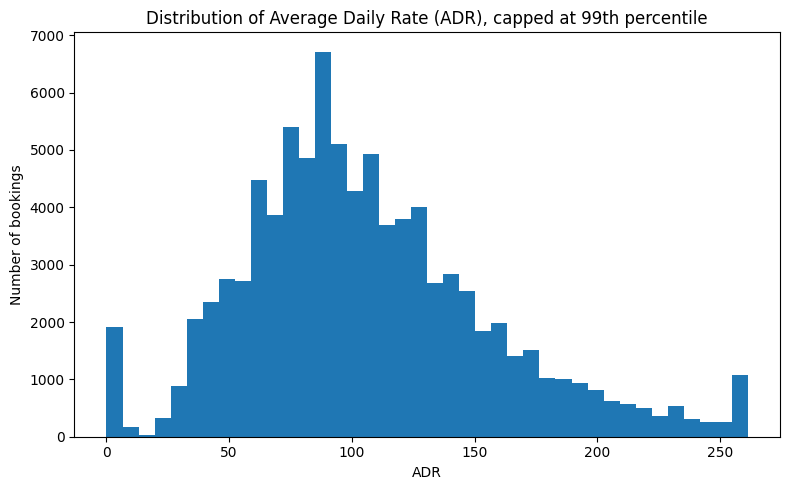

In [13]:
# 1. Histogram: ADR distribution (capped for readability)
plt.figure(figsize=(8, 5))
plt.hist(df_clean["adr_capped"], bins=40)
plt.title("Distribution of Average Daily Rate (ADR), capped at 99th percentile")
plt.xlabel("ADR")
plt.ylabel("Number of bookings")
plt.tight_layout()
plt.show()

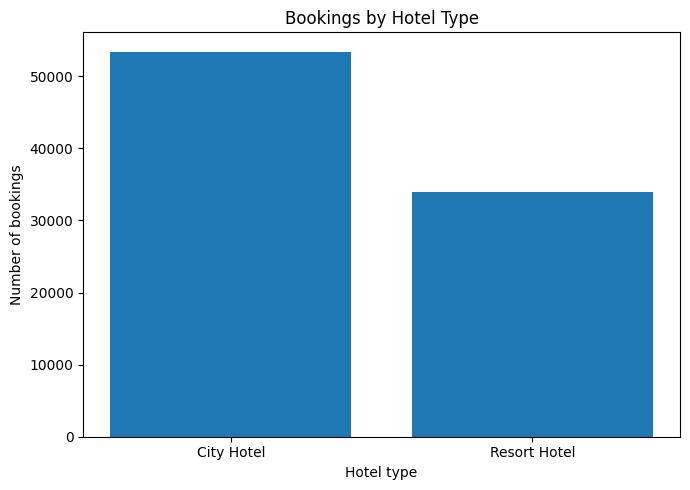

In [14]:
# 2. Bar chart: bookings by hotel type
hotel_counts = df_clean["hotel"].value_counts()
plt.figure(figsize=(7, 5))
plt.bar(hotel_counts.index, hotel_counts.values)
plt.title("Bookings by Hotel Type")
plt.xlabel("Hotel type")
plt.ylabel("Number of bookings")
plt.tight_layout()
plt.show()

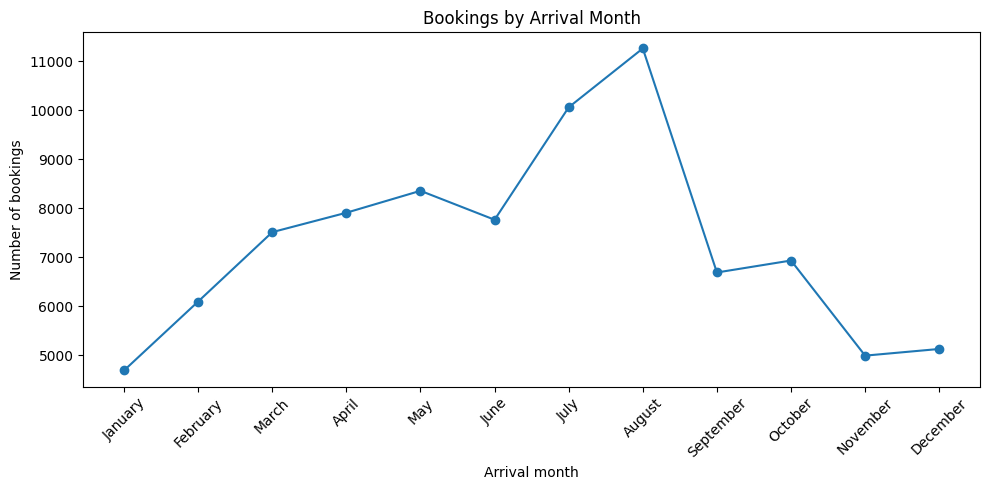

In [15]:
# 3. Line chart: bookings by arrival month (month order)
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
monthly = df_clean.groupby("arrival_date_month").size().reindex(month_order)
plt.figure(figsize=(10, 5))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Bookings by Arrival Month")
plt.xlabel("Arrival month")
plt.ylabel("Number of bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

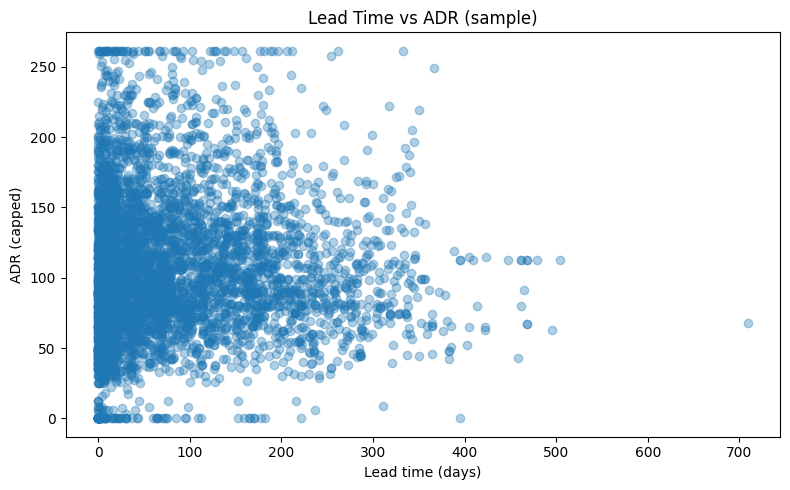

In [16]:
# 4. Scatter plot: lead time vs ADR (sample to make plot readable)
sample = df_clean.sample(min(5000, len(df_clean)), random_state=42)
plt.figure(figsize=(8, 5))
plt.scatter(sample["lead_time"], sample["adr_capped"], alpha=0.35)
plt.title("Lead Time vs ADR (sample)")
plt.xlabel("Lead time (days)")
plt.ylabel("ADR (capped)")
plt.tight_layout()
plt.show()

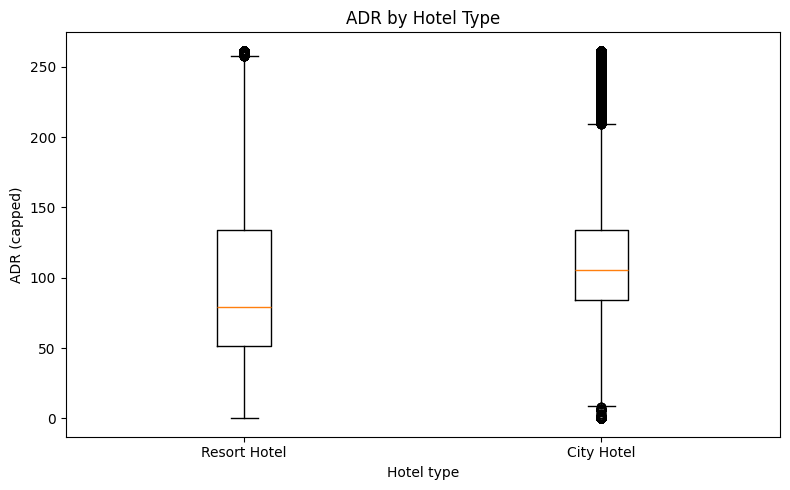

In [17]:
# 5. Box plot: ADR by hotel type
plt.figure(figsize=(8, 5))
data_to_plot = [df_clean.loc[df_clean["hotel"] == h, "adr_capped"] for h in df_clean["hotel"].unique()]
plt.boxplot(data_to_plot, labels=df_clean["hotel"].unique())
plt.title("ADR by Hotel Type")
plt.xlabel("Hotel type")
plt.ylabel("ADR (capped)")
plt.tight_layout()
plt.show()

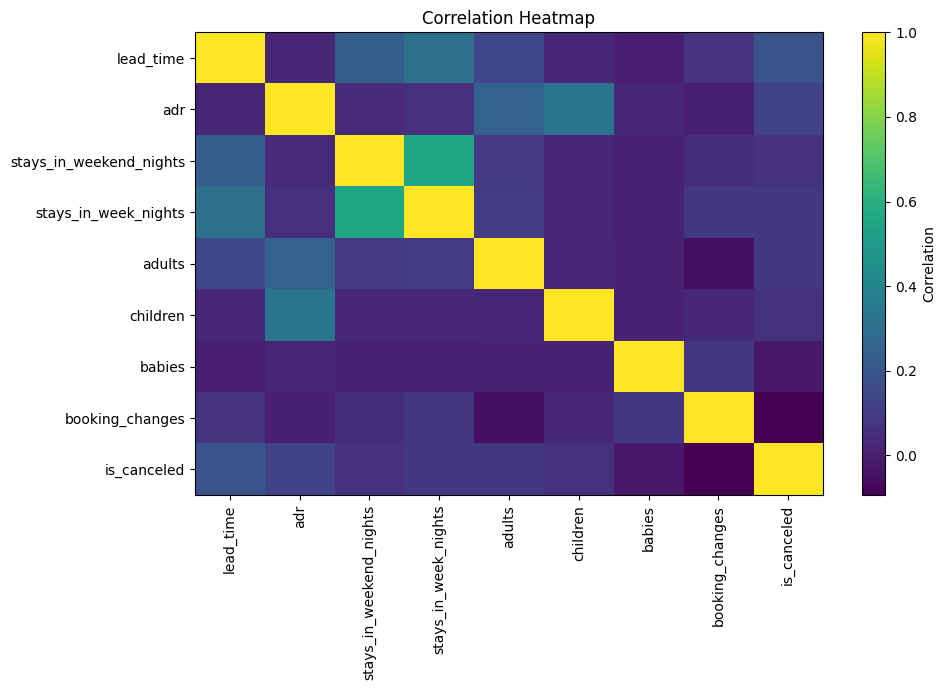

In [18]:
# 6. Correlation heatmap (numerical features)
corr_cols = ["lead_time", "adr", "stays_in_weekend_nights", "stays_in_week_nights",
              "adults", "children", "babies", "booking_changes", "is_canceled"]
corr = df_clean[corr_cols].corr()
plt.figure(figsize=(10, 7))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr_cols)), corr_cols, rotation=90)
plt.yticks(range(len(corr_cols)), corr_cols)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## Step 7 — Interactive Visualizations using Plotly
Plotly charts are interactive: hover over points/bars, zoom, and explore values.

In [19]:
# Interactive histogram
fig = px.histogram(df_clean, x="adr_capped", color="hotel", nbins=40,
                   title="Interactive ADR Distribution by Hotel Type",
                   labels={"adr_capped": "ADR (capped)", "count": "Bookings"})
fig.show()

In [20]:
# Interactive scatter plot
fig = px.scatter(sample, x="lead_time", y="adr_capped", color="hotel",
                 hover_data=["is_canceled", "market_segment"],
                 title="Interactive Lead Time vs ADR")
fig.show()

In [21]:
# Interactive bar chart: cancellations by hotel type
cancel_summary = df_clean.groupby("hotel")["is_canceled"].mean().mul(100).reset_index(name="cancellation_rate_percent")
fig = px.bar(cancel_summary, x="hotel", y="cancellation_rate_percent",
              title="Cancellation Rate by Hotel Type (%)",
              labels={"hotel": "Hotel type", "cancellation_rate_percent": "Cancellation rate (%)"},
              hover_data={"cancellation_rate_percent": ":.2f"})
fig.show()

## Step 8 — Feature Engineering
Create new variables that summarize the booking and support further analysis. Date fields are combined into an arrival date, then month and weekday are extracted. We also encode hotel type and scale selected numerical columns as examples.

In [22]:
# 1. Total guests in the booking
df_clean["total_guests"] = df_clean["adults"] + df_clean["children"] + df_clean["babies"]

# 2. Total stay nights
df_clean["total_stay_nights"] = (df_clean["stays_in_weekend_nights"] +
                                  df_clean["stays_in_week_nights"])

# 3. Total room nights (guest count × nights)
df_clean["total_guest_nights"] = df_clean["total_guests"] * df_clean["total_stay_nights"]

# 4. Arrival date and extracted calendar features
df_clean["arrival_date"] = pd.to_datetime(
    df_clean["arrival_date_year"].astype(str) + "-" +
    df_clean["arrival_date_month"] + "-" +
    df_clean["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d", errors="coerce"
)
df_clean["arrival_month_num"] = df_clean["arrival_date"].dt.month
df_clean["arrival_weekday"] = df_clean["arrival_date"].dt.day_name()

# 5. Binary encoding for hotel type (Resort=1, City=0)
df_clean["is_resort_hotel"] = (df_clean["hotel"] == "Resort Hotel").astype(int)

# Demonstration of min-max scaling for lead time
lead_min = df_clean["lead_time"].min()
lead_max = df_clean["lead_time"].max()
df_clean["lead_time_scaled"] = (df_clean["lead_time"] - lead_min) / (lead_max - lead_min)

display(df_clean[["hotel", "total_guests", "total_stay_nights", "total_guest_nights",
                  "arrival_date", "arrival_month_num", "arrival_weekday",
                  "is_resort_hotel", "lead_time_scaled"]].head())

,hotel,total_guests,total_stay_nights,total_guest_nights,arrival_date,arrival_month_num,arrival_weekday,is_resort_hotel,lead_time_scaled
0,Resort Hotel,2.0,0,0.0,2015-07-01,7,Wednesday,1,0.464043
1,Resort Hotel,2.0,0,0.0,2015-07-01,7,Wednesday,1,1.000000
2,Resort Hotel,1.0,1,1.0,2015-07-01,7,Wednesday,1,0.009498
3,Resort Hotel,1.0,1,1.0,2015-07-01,7,Wednesday,1,0.017639
4,Resort Hotel,2.0,2,4.0,2015-07-01,7,Wednesday,1,0.018996


### Why these engineered features matter
- **total_guests:** captures booking party size and helps compare customer groups.
- **total_stay_nights:** measures stay duration in one value.
- **total_guest_nights:** approximates total guest accommodation demand.
- **arrival_month_num / arrival_weekday:** supports seasonal and weekday/weekend analysis.
- **is_resort_hotel:** converts hotel category into a numeric variable for analysis or modeling.
- **lead_time_scaled:** rescales lead time to 0–1 for algorithms sensitive to feature scale.

## Step 9 — Analysis, Findings, and Conclusions
The following code calculates evidence-based summary values. Review the output and use it to write final observations. The assignment requires at least five observations and three recommendations; the template below prints statistics to support them.

In [23]:
# Evidence-based findings from this dataset
hotel_booking_counts = df_clean["hotel"].value_counts()
cancel_rates = df_clean.groupby("hotel")["is_canceled"].mean().mul(100)
monthly_booking_counts = df_clean.groupby("arrival_date_month").size().reindex(month_order)
top_month = monthly_booking_counts.idxmax()
lowest_month = monthly_booking_counts.idxmin()
print("1. Booking count by hotel type:\\n", hotel_booking_counts)
print("\\n2. Cancellation rates by hotel (%):\\n", cancel_rates.round(2))
print(f"\\n3. Most bookings by arrival month: {top_month} ({monthly_booking_counts[top_month]:,})")
print(f"4. Fewest bookings by arrival month: {lowest_month} ({monthly_booking_counts[lowest_month]:,})")
print(f"5. Median lead time (days): {df_clean['lead_time'].median():.1f}")
print(f"6. Median ADR: {df_clean['adr'].median():.2f}")
print(f"7. Median stay length (nights): {df_clean['total_stay_nights'].median():.1f}")
print(f"8. Share of bookings with children/babies (%): {(df_clean['total_guests'] > df_clean['adults']).mean()*100:.2f}")

1. Booking count by hotel type:\n hotel
City Hotel      53428
Resort Hotel    33967
Name: count, dtype: int64
\n2. Cancellation rates by hotel (%):\n hotel
City Hotel      30.04
Resort Hotel    23.48
Name: is_canceled, dtype: float64
\n3. Most bookings by arrival month: August (11,257)
4. Fewest bookings by arrival month: January (4,693)
5. Median lead time (days): 49.0
6. Median ADR: 98.10
7. Median stay length (nights): 3.0
8. Share of bookings with children/babies (%): 10.42


### Observations (from the cleaned dataset)
1. **City Hotel** has more bookings (53,428) than **Resort Hotel** (33,967).
2. Cancellation rate is higher for City Hotel (30.04%) than Resort Hotel (23.48%).
3. **August** has the highest number of arrivals (11,257), followed by July (10,057).
4. May is among the next busiest months (8,355 bookings); arrival demand varies by month.
5. Median lead time is **49 days**—half of bookings were made 49 days or less before arrival.
6. Median stay duration is **3 nights**.
7. Median ADR is **98.10**; the mean ADR is higher (about 106.34), suggesting high-price values pull the average upward.
8. About **10.42%** of bookings include children or babies (based on guest-count comparison).

### Recommendations
1. Use monthly booking patterns to plan staffing, inventory, and seasonal pricing, with extra preparation for summer peaks.
2. Review cancellation behavior by hotel type and booking channel; consider clear cancellation policies and reminder communication.
3. Use lead time and guest/stay features to segment bookings and support targeted offers.

### Limitations
- The dataset represents a historical period and may not describe current hotel demand.
- Some identifiers (agent/company) have extensive missing values.
- Correlation does not prove causation.
- Extreme prices and unusual bookings can affect averages; medians and capped plots help reduce their visual impact.
- Data cleaning choices (duplicate removal and missing-value treatment) may affect results.

In [24]:
# Optional: export cleaned dataset for further work
df_clean.to_csv("hotel_bookings_cleaned.csv", index=False)
print("Saved cleaned dataset as hotel_bookings_cleaned.csv")

Saved cleaned dataset as hotel_bookings_cleaned.csv
